# Introduction
This notebook verifies that the micW device records the same sound as the B&K probe microphone. For these tests, we played two different WAV files in the same tube (1.25CC calibration tube) and recorded data through the Tympan of the micW, and also using the B&K probe mic. 

In [1]:
# Configure plotting
# %matplotlib widget  # For interactive plots
%matplotlib inline

In [2]:
# Import relevant libraries
import os
from matplotlib import pyplot as plt
import numpy as np
from scipy import ndimage
from auren.core import io
from auren.core import signal_processing_utils as spu
from auren.core.utils import todB
import auren.core.data_models as adm


In [3]:
# Load the data
base_path = "/mnt/c/Repositories/OpenHearing/data/2024-12-10_AurenMicWB&KCheck"
mw0_path = os.path.join(base_path, "AUDIO020.WAV")
mw1_path = os.path.join(base_path, "AUDIO021.WAV")
bk0_path = os.path.join(base_path, "BKProbe_003.WAV")
bk1_path = os.path.join(base_path, "BKProbe_004.WAV")
# bk0_path = os.path.join(base_path, "BKProbe_001.WAV")
# bk1_path = os.path.join(base_path, "BKProbe_002.WAV")

mw_time, mw0_amp, mw_samplerate = io.load_wav(mw0_path)
_, mw1_amp, _ = io.load_wav(mw1_path)
bk_time, bk0_amp, bk_samplerate = io.load_wav(bk0_path)
_, bk1_amp, _ = io.load_wav(bk1_path)

Using scaling data from  /mnt/c/Repositories/OpenHearing/data/2024-12-10_AurenMicWB&KCheck/BKProbe_003.dat
Using scaling data from  /mnt/c/Repositories/OpenHearing/data/2024-12-10_AurenMicWB&KCheck/BKProbe_004.dat


In [4]:
# Scale the micW data, as appropriate
tympan_FS_voltage = 0.375 * 10** (8.8 / 20)  # This scaling was read off the plot below. In the next cell, we see the actual scale that should have been used.
micw_calibration = 9.8 # 9.8 #~~mv/Pa~~ 3.83 Pa/

mw0_amp_s = mw0_amp * tympan_FS_voltage * 1000 / micw_calibration  # V * 1000mV / V / (mV / Pa) = Pa
mw1_amp_s = mw1_amp * tympan_FS_voltage * 1000 / micw_calibration  # V * 1000mV / V / (mV / Pa) = Pa

In [5]:
print("Tympan FS voltage", tympan_FS_voltage, "Tympan RMS voltage", tympan_FS_voltage / np.sqrt(2), "micW RMS calibration", micw_calibration / np.sqrt(2))


Tympan FS voltage 1.0328357637518124 Tympan RMS voltage 0.7303251724008935 micW RMS calibration 6.929646455628165


In [6]:
# Trim the data
# Start by creating the reference tone data
tone = adm.chirp.Chirp(durations=[10], frequencies=[200, 20000], samplerate=mw_samplerate)
_, real_base, f_at_sample = tone.get(return_freq=True)
_, imag_base = tone.get(phi=np.pi/2)
trim_freq = 10e3
# Now trim
mw0_amp_trim, _ = spu.trim_signal_max_correlation_at_f(mw0_amp_s[None, None, :, 0], f_at_sample, trim_freq, real_base, imag_base, 1024, False)
mw1_amp_trim, _ = spu.trim_signal_max_correlation_at_f(mw1_amp_s[None, None, :, 0], f_at_sample, trim_freq, real_base, imag_base, 1024, False)
# Repeat for the B&K (same tone, but different samplerate)
tone.samplerate = bk_samplerate
_, real_base, f_at_sample = tone.get(return_freq=True)
_, imag_base = tone.get(phi=np.pi/2)
bk0_amp_trim, _ = spu.trim_signal_max_correlation_at_f(bk0_amp[None, None, :], f_at_sample, trim_freq, real_base, imag_base, 1024, False)
bk1_amp_trim, _ = spu.trim_signal_max_correlation_at_f(bk1_amp[None, None, :], f_at_sample, trim_freq, real_base, imag_base, 1024, False)

In [7]:
# Frequency domain
mw_f, mw0_p = spu.to_fourier(mw0_amp_trim.squeeze(), mw_samplerate)
_, mw1_p = spu.to_fourier(mw1_amp_trim.squeeze(), mw_samplerate)
bk_f, bk0_p = spu.to_fourier(bk0_amp_trim.squeeze(), bk_samplerate)
_, bk1_p = spu.to_fourier(bk1_amp_trim.squeeze(), bk_samplerate)

# Smooth accross frequencies
sigma=18
mw0_ps = ndimage.gaussian_filter1d(np.abs(mw0_p), sigma=sigma, truncate=2.5)
mw1_ps = ndimage.gaussian_filter1d(np.abs(mw1_p), sigma=sigma, truncate=2.5)
bk0_ps = ndimage.gaussian_filter1d(np.abs(bk0_p), sigma=sigma, truncate=2.5)
bk1_ps = ndimage.gaussian_filter1d(np.abs(bk1_p), sigma=sigma, truncate=2.5)

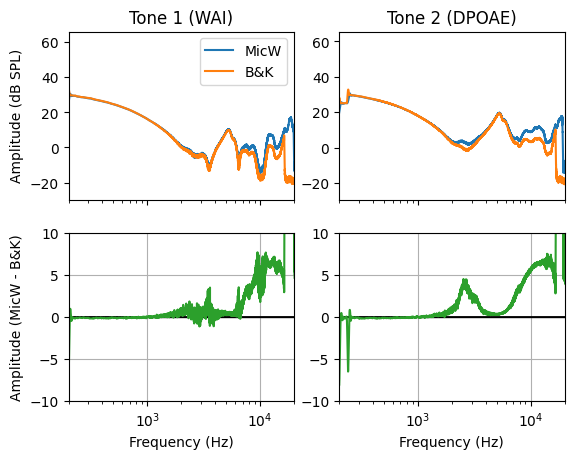

In [8]:
# Plot results
plt.close('all')
fig, axs = plt.subplots(2, 2, sharex=True)
# Absolute magnitude plots
axs[0, 0].semilogx(mw_f, todB(mw0_ps), label='MicW')
axs[0, 0].semilogx(bk_f, todB(bk0_ps), label='B&K')
axs[0, 0].set_xlim(200, 20000)
# axs[0, 0].set_xlabel("Frequency (Hz)")
axs[0, 0].set_ylabel("Amplitude (dB SPL)")
axs[0, 0].set_title("Tone 1 (WAI)")
axs[0, 0].legend()
axs[0, 1].semilogx(mw_f, todB(mw1_ps), label='MicW')
axs[0, 1].semilogx(bk_f, todB(bk1_ps), label='B&K')
axs[0, 1].set_xlim(200, 20000)
# axs[0, 1].set_xlabel("Frequency (Hz)")
# axs[0, 1].set_ylabel("Amplitude (dB SPL)")
axs[0, 1].set_title("Tone 2 (DPOAE)")
# Difference plots
axs[1, 0].semilogx(mw_f, mw_f*0, 'k')
axs[1, 0].semilogx(mw_f, todB(mw0_ps) - np.interp(mw_f, bk_f, todB(bk0_ps)), "C2", label='MicW - B&K')
axs[1, 0].set_xlim(200, 20000)
axs[1, 0].set_xlabel("Frequency (Hz)")
axs[1, 0].set_ylabel("Amplitude (MicW - B&K)")
axs[1, 0].grid()
axs[1, 0].set_ylim(-10, 10)
axs[1, 1].semilogx(mw_f, mw_f*0, 'k')
axs[1, 1].semilogx(mw_f, todB(mw1_ps) - np.interp(mw_f, bk_f, todB(bk1_ps)), "C2", label='MicW - B&K')
axs[1, 1].set_xlim(200, 20000)
axs[1, 1].set_ylim(-10, 10)
axs[1, 1].set_xlabel("Frequency (Hz)")
axs[1, 1].grid()
# axs[1, 1].set_ylabel("Amplitude (MicW - B&K)")

Text(0.5, 0, 'Frequency (Hz)')

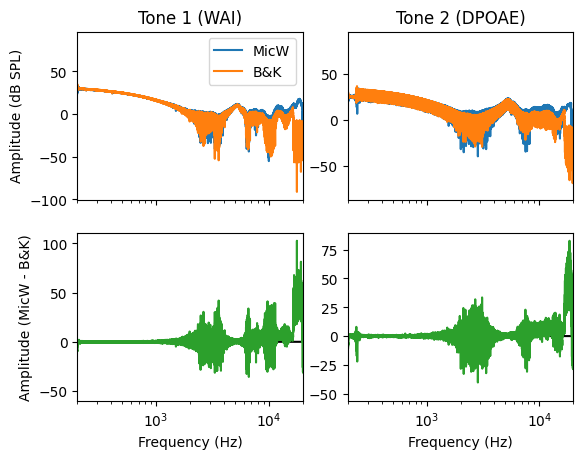

In [9]:
# Plot results
plt.close('all')
fig, axs = plt.subplots(2, 2, sharex=True)
# Absolute magnitude plots
axs[0, 0].semilogx(mw_f, todB(mw0_p), label='MicW')
axs[0, 0].semilogx(bk_f, todB(bk0_p), label='B&K')
axs[0, 0].set_xlim(200, 20000)
# axs[0, 0].set_xlabel("Frequency (Hz)")
axs[0, 0].set_ylabel("Amplitude (dB SPL)")
axs[0, 0].set_title("Tone 1 (WAI)")
axs[0, 0].legend()
axs[0, 1].semilogx(mw_f, todB(mw1_p), label='MicW')
axs[0, 1].semilogx(bk_f, todB(bk1_p), label='B&K')
axs[0, 1].set_xlim(200, 20000)
# axs[0, 1].set_xlabel("Frequency (Hz)")
# axs[0, 1].set_ylabel("Amplitude (dB SPL)")
axs[0, 1].set_title("Tone 2 (DPOAE)")
# Difference plots
axs[1, 0].semilogx(mw_f, mw_f*0, 'k')
axs[1, 0].semilogx(mw_f, todB(mw0_p) - np.interp(mw_f, bk_f, todB(bk0_p)), "C2", label='MicW - B&K')
axs[1, 0].set_xlim(200, 20000)
axs[1, 0].set_xlabel("Frequency (Hz)")
axs[1, 0].set_ylabel("Amplitude (MicW - B&K)")
axs[1, 1].semilogx(mw_f, mw_f*0, 'k')
axs[1, 1].semilogx(mw_f, todB(mw1_p) - np.interp(mw_f, bk_f, todB(bk1_p)), "C2", label='MicW - B&K')
axs[1, 1].set_xlim(200, 20000)
axs[1, 1].set_xlabel("Frequency (Hz)")
# axs[1, 1].set_ylabel("Amplitude (MicW - B&K)")

Text(0.5, 0, 'Frequency (Hz)')

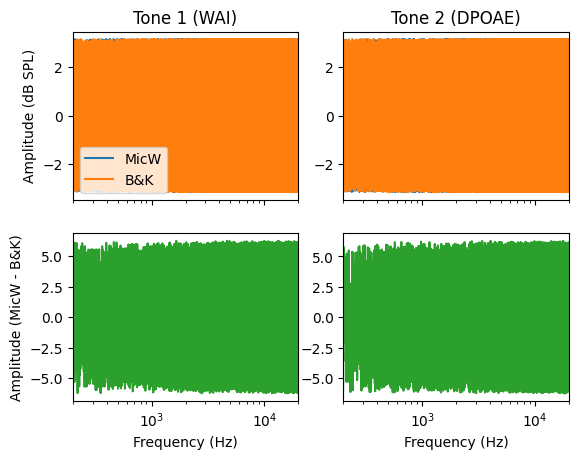

In [10]:
# Plot results
plt.close('all')
fig, axs = plt.subplots(2, 2, sharex=True)
# Absolute magnitude plots
axs[0, 0].semilogx(mw_f, np.angle(mw0_p), label='MicW')
axs[0, 0].semilogx(bk_f, np.angle(bk0_p), label='B&K')
axs[0, 0].set_xlim(200, 20000)
# axs[0, 0].set_xlabel("Frequency (Hz)")
axs[0, 0].set_ylabel("Amplitude (dB SPL)")
axs[0, 0].set_title("Tone 1 (WAI)")
axs[0, 0].legend()
axs[0, 1].semilogx(mw_f, np.angle(mw1_p), label='MicW')
axs[0, 1].semilogx(bk_f, np.angle(bk1_p), label='B&K')
axs[0, 1].set_xlim(200, 20000)
# axs[0, 1].set_xlabel("Frequency (Hz)")
# axs[0, 1].set_ylabel("Amplitude (dB SPL)")
axs[0, 1].set_title("Tone 2 (DPOAE)")
# Difference plots
axs[1, 0].semilogx(mw_f, mw_f*0, 'k')
axs[1, 0].semilogx(mw_f, np.angle(mw0_p) - np.interp(mw_f, bk_f, np.angle(bk0_p)), "C2", label='MicW - B&K')
axs[1, 0].set_xlim(200, 20000)
axs[1, 0].set_xlabel("Frequency (Hz)")
axs[1, 0].set_ylabel("Amplitude (MicW - B&K)")
axs[1, 1].semilogx(mw_f, mw_f*0, 'k')
axs[1, 1].semilogx(mw_f, np.angle(mw1_p) - np.interp(mw_f, bk_f, np.angle(bk1_p)), "C2", label='MicW - B&K')
axs[1, 1].set_xlim(200, 20000)
axs[1, 1].set_xlabel("Frequency (Hz)")
# axs[1, 1].set_ylabel("Amplitude (MicW - B&K)")